# SRGAN for Cats-vs-Dogs Classification
**Applied AI Midterm** · Sayan Paul, UNC Charlotte · based on Ledig et al., CVPR 2017 ([arXiv:1609.04802](https://arxiv.org/abs/1609.04802))

Train classifier A on 128×128 images, train an SRGAN (32×32 → 128×128), train classifier B on the generated images, and compare. Dataset: 12,000 images.

## 0. Setup

In [1]:
# Google Drive (Colab only)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('Running in Colab:', IN_COLAB)

Running in Colab: False


In [2]:
!nvidia-smi -L || echo "No GPU detected - enable one via Runtime > Change runtime type"

GPU 0: NVIDIA GeForce RTX 3060 (UUID: GPU-fc01ee51-e873-26fb-c828-318d5c605e62)


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

import glob, json, random, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm


from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device)

torch 2.14.1+cu126 | device: cuda


## 1. Configuration

In [4]:
SMOKE_TEST = False

SEED          = 42
IMG_HR        = 128
IMG_LR        = 32
N_PER_CLASS   = 6000
TEST_FRAC     = 0.30         # 70 % train / 30 % test

# classifiers (A and B)
CLS_EPOCHS    = 10
CLS_BATCH     = 32
CLS_LR        = 1e-4

# SRGAN
SRRESNET_EPOCHS = 20
SRGAN_EPOCHS    = 150
SR_BATCH        = 16         # paper uses 16
SR_LR           = 1e-4
N_RES_BLOCKS    = 16
CONTENT_W       = 0.006
ADV_W           = 1e-3
SAVE_EVERY      = 5
USE_AMP         = True
NUM_WORKERS     = 0 if os.name == 'nt' else 2

if SMOKE_TEST:
    N_PER_CLASS, CLS_EPOCHS, SRRESNET_EPOCHS, SRGAN_EPOCHS, SAVE_EVERY = 40, 2, 1, 2, 1

PROJECT_DIR = '/content/drive/MyDrive/AppliedAI_Midterm_SRGAN_12000' if IN_COLAB else './AppliedAI_Midterm_SRGAN_12000'
if SMOKE_TEST:
    PROJECT_DIR += '_smoke'
DATA_DIR    = os.path.join(PROJECT_DIR, 'data')
CKPT_DIR    = os.path.join(PROJECT_DIR, 'checkpoints')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
for d in (DATA_DIR, CKPT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

AMP = USE_AMP and device.type == 'cuda'
CLASSES = ['Cat', 'Dog']     # label 0 = Cat, label 1 = Dog
print('Project folder:', PROJECT_DIR)

def savefig(name):
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150, bbox_inches='tight')

Project folder: ./AppliedAI_Midterm_SRGAN_12000


## 2. Dataset
Cats vs Dogs, resized to 128×128 and split 70/30 (stratified).

In [5]:
CACHE_HR = os.path.join(DATA_DIR, f'catsdogs_{IMG_HR}px_{N_PER_CLASS}perclass.npz')
URL = 'https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip'

def load_hr_dataset():
    if os.path.exists(CACHE_HR):
        d = np.load(CACHE_HR)
        return d['X'], d['y']
    base = '/content' if IN_COLAB else DATA_DIR
    zip_path, root = os.path.join(base, 'catsdogs.zip'), os.path.join(base, 'catsdogs')
    if not os.path.isdir(os.path.join(root, 'PetImages')):
        if not os.path.exists(zip_path):
            print('Downloading dataset (~800 MB)...')
            urllib.request.urlretrieve(URL, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(root)
    X, y = [], []
    rng = random.Random(SEED)
    for label, cls in enumerate(CLASSES):
        files = sorted(glob.glob(os.path.join(root, 'PetImages', cls, '*.jpg')))
        rng.shuffle(files)
        kept = 0
        for f in tqdm(files, desc=f'{cls}'):
            try:
                with Image.open(f) as im:
                    im = im.convert('RGB').resize((IMG_HR, IMG_HR), Image.BICUBIC)
                    X.append(np.asarray(im, dtype=np.uint8)); y.append(label)
                    kept += 1
            except Exception:
                continue            # skip corrupt / unreadable files
            if kept >= N_PER_CLASS:
                break
    X, y = np.stack(X), np.array(y, dtype=np.int64)
    np.savez_compressed(CACHE_HR, X=X, y=y)
    return X, y

X_hr, y = load_hr_dataset()
print('HR images:', X_hr.shape, '| class counts:', np.bincount(y))

Cat:   0%|          | 0/12500 [00:00<?, ?it/s]

Dog:   0%|          | 0/12500 [00:00<?, ?it/s]

C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


HR images: (12000, 128, 128, 3) | class counts: [6000 6000]


In [6]:
# 70/30 stratified split
idx = np.arange(len(y))
train_idx, test_idx = train_test_split(idx, test_size=TEST_FRAC, stratify=y, random_state=SEED)
np.savez(os.path.join(DATA_DIR, 'split_indices.npz'), train_idx=train_idx, test_idx=test_idx)
y_train, y_test = y[train_idx], y[test_idx]
print(f'Train: {len(train_idx)}  ({np.bincount(y_train)})   Test: {len(test_idx)}  ({np.bincount(y_test)})')

Train: 8400  ([4200 4200])   Test: 3600  ([1800 1800])


## 3. Normalization and transformations

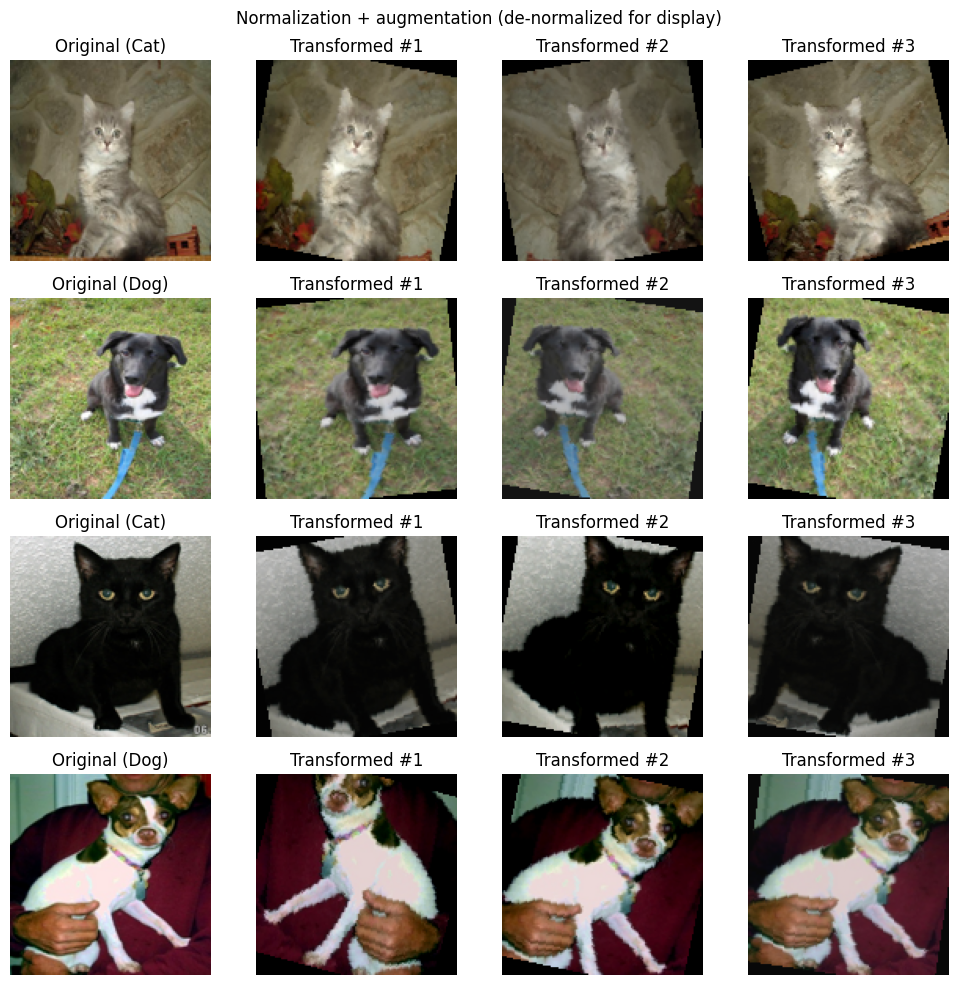

In [7]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(IMG_HR, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
test_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class ArrayDataset(Dataset):
    """Wraps a uint8 array (N,H,W,3) + labels with a torchvision transform."""
    def __init__(self, X, y, tf):
        self.X, self.y, self.tf = X, y, tf
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.tf(self.X[i]), torch.tensor(self.y[i], dtype=torch.float32)

def denorm(t):
    m = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); s = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r, i in enumerate(train_idx[:4]):
    axes[r, 0].imshow(X_hr[i]); axes[r, 0].set_title(f'Original ({CLASSES[y[i]]})')
    for c in range(1, 4):
        axes[r, c].imshow(denorm(train_tf(X_hr[i]))); axes[r, c].set_title(f'Transformed #{c}')
for a in axes.ravel(): a.axis('off')
plt.suptitle('Normalization + augmentation (de-normalized for display)'); plt.tight_layout()
savefig('transformed_samples.png'); plt.show()

## 4. Model A: ResNet-18 transfer learning on real 128×128 images

modelA epoch 1/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelA | epoch   1 | loss 0.1750 | train acc 0.9305 | test acc 0.9639


modelA epoch 2/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelA | epoch   2 | loss 0.0966 | train acc 0.9612 | test acc 0.9597


modelA epoch 3/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelA | epoch   3 | loss 0.0752 | train acc 0.9705 | test acc 0.9550


... (10 outputs left out)

modelA epoch 9/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelA | epoch   9 | loss 0.0294 | train acc 0.9884 | test acc 0.9711


modelA epoch 10/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelA | epoch  10 | loss 0.0313 | train acc 0.9889 | test acc 0.9728


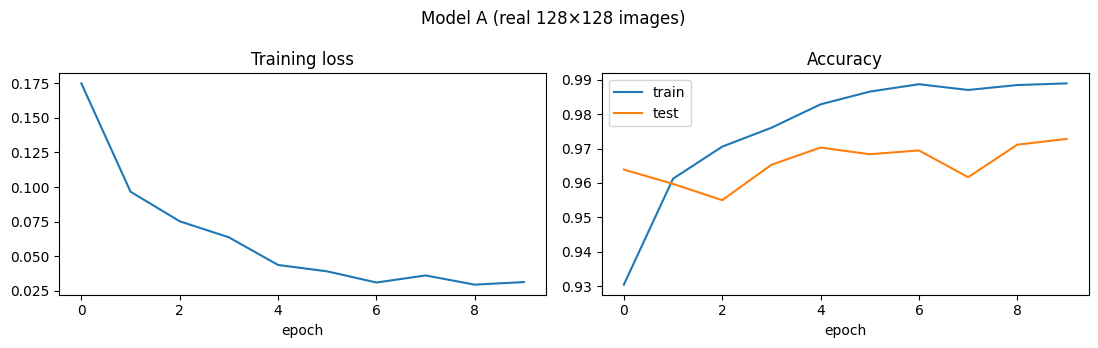

In [8]:
def build_classifier():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(device)

@torch.no_grad()
def predict(model, X, y_true, batch=128):
    model.eval()
    loader = DataLoader(ArrayDataset(X, y_true, test_tf), batch_size=batch, shuffle=False, num_workers=NUM_WORKERS)
    probs = []
    for xb, _ in loader:
        with torch.autocast(device.type, enabled=AMP):
            probs.append(torch.sigmoid(model(xb.to(device)).float()).squeeze(1).cpu())
    return torch.cat(probs).numpy()

def train_classifier(name, X_tr, y_tr, X_te, y_te, epochs=CLS_EPOCHS):
    seed_everything()
    model = build_classifier()
    opt = torch.optim.Adam(model.parameters(), lr=CLS_LR)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    crit = nn.BCEWithLogitsLoss()
    last = os.path.join(CKPT_DIR, f'{name}_last.pt')
    hist, start = {'train_loss': [], 'train_acc': [], 'test_acc': []}, 0
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
        hist, start = ck['hist'], ck['epoch'] + 1
        print(f'Resuming {name} from epoch {start}')
    loader = DataLoader(ArrayDataset(X_tr, y_tr, train_tf), batch_size=CLS_BATCH, shuffle=True,
                        num_workers=NUM_WORKERS, drop_last=True)
    for ep in range(start, epochs):
        model.train(); tot, correct, n = 0.0, 0, 0
        for xb, yb in tqdm(loader, desc=f'{name} epoch {ep+1}/{epochs}', leave=False):
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=AMP):
                logits = model(xb).squeeze(1)
                loss = crit(logits.float(), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(yb); correct += ((logits > 0).float() == yb).sum().item(); n += len(yb)
        test_acc = accuracy_score(y_te, predict(model, X_te, y_te) > 0.5)
        hist['train_loss'].append(tot / n); hist['train_acc'].append(correct / n); hist['test_acc'].append(test_acc)
        print(f'{name} | epoch {ep+1:3d} | loss {tot/n:.4f} | train acc {correct/n:.4f} | test acc {test_acc:.4f}')
        ck = {'model': model.state_dict(), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(), 'hist': hist, 'epoch': ep}
        torch.save(ck, last)
        if (ep + 1) % SAVE_EVERY == 0 or ep + 1 == epochs:
            torch.save(model.state_dict(), os.path.join(CKPT_DIR, f'{name}_epoch{ep+1:03d}.pt'))
    torch.save(model.state_dict(), os.path.join(CKPT_DIR, f'{name}_final.pt'))
    return model, hist

def plot_history(hist, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist['train_loss']); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
    ax[1].plot(hist['train_acc'], label='train'); ax[1].plot(hist['test_acc'], label='test')
    ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

model_A, hist_A = train_classifier('modelA', X_hr[train_idx], y_train, X_hr[test_idx], y_test)
plot_history(hist_A, 'Model A (real 128×128 images)', 'modelA_history.png')

## 5. Downscaling to 32×32

LR images: (12000, 32, 32, 3)


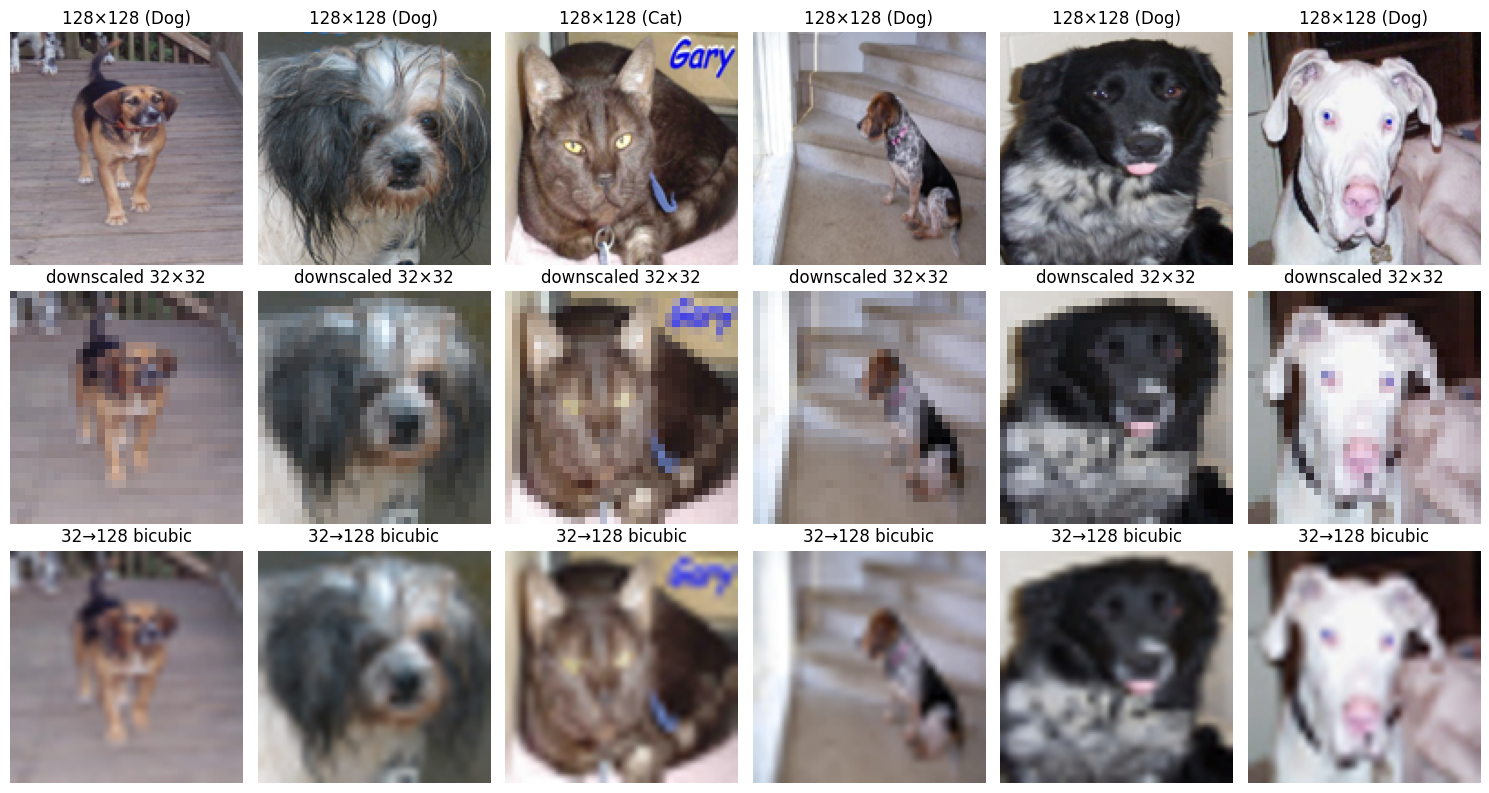

In [9]:
def downscale(X, size=IMG_LR):
    return np.stack([np.asarray(Image.fromarray(x).resize((size, size), Image.BICUBIC)) for x in X])

def bicubic_up(X, size=IMG_HR):
    return np.stack([np.asarray(Image.fromarray(x).resize((size, size), Image.BICUBIC)) for x in X])

X_lr = downscale(X_hr)
print('LR images:', X_lr.shape)

show = test_idx[:6]
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for c, i in enumerate(show):
    axes[0, c].imshow(X_hr[i]); axes[0, c].set_title(f'128×128 ({CLASSES[y[i]]})')
    axes[1, c].imshow(X_lr[i], interpolation='nearest'); axes[1, c].set_title('downscaled 32×32')
    axes[2, c].imshow(bicubic_up(X_lr[i:i+1])[0]); axes[2, c].set_title('32→128 bicubic')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); savefig('scaled_examples.png'); plt.show()

## 6. SRGAN architecture
SRResNet generator (16 residual blocks, 2× PixelShuffle), VGG-style discriminator, VGG-19 φ5,4 perceptual loss.

In [10]:
class ResidualBlock(nn.Module):
    def __init__(self, c=64):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c, c, 3, 1, 1), nn.BatchNorm2d(c), nn.PReLU(c),
            nn.Conv2d(c, c, 3, 1, 1), nn.BatchNorm2d(c))
    def forward(self, x):
        return x + self.block(x)

class UpsampleBlock(nn.Module):
    def __init__(self, c=64):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(c, c * 4, 3, 1, 1), nn.PixelShuffle(2), nn.PReLU(c))
    def forward(self, x):
        return self.block(x)

class Generator(nn.Module):
    def __init__(self, n_res=N_RES_BLOCKS, c=64):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, c, 9, 1, 4), nn.PReLU(c))
        self.body = nn.Sequential(*[ResidualBlock(c) for _ in range(n_res)],
                                  nn.Conv2d(c, c, 3, 1, 1), nn.BatchNorm2d(c))
        self.up   = nn.Sequential(UpsampleBlock(c), UpsampleBlock(c))   # 2 x 2 = 4x
        self.tail = nn.Conv2d(c, 3, 9, 1, 4)
    def forward(self, x):
        h = self.head(x)
        return torch.tanh(self.tail(self.up(h + self.body(h))))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout, stride, bn=True):
            layers = [nn.Conv2d(cin, cout, 3, stride, 1)]
            if bn: layers.append(nn.BatchNorm2d(cout))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers
        self.features = nn.Sequential(
            *block(3, 64, 1, bn=False), *block(64, 64, 2),
            *block(64, 128, 1),  *block(128, 128, 2),
            *block(128, 256, 1), *block(256, 256, 2),
            *block(256, 512, 1), *block(512, 512, 2))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((6, 6)), nn.Flatten(),
            nn.Linear(512 * 6 * 6, 1024), nn.LeakyReLU(0.2, inplace=True), nn.Linear(1024, 1))
    def forward(self, x):
        return self.classifier(self.features(x))

class VGGContentLoss(nn.Module):
    """MSE between VGG-19 phi_{5,4} feature maps (after ReLU) of SR and HR images."""
    def __init__(self):
        super().__init__()
        vgg = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1).features[:36].eval()
        for p in vgg.parameters(): p.requires_grad = False
        self.vgg = vgg
        self.register_buffer('mean', torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))
    def forward(self, sr, hr):                       # inputs in [-1, 1]
        sr = ((sr + 1) / 2 - self.mean) / self.std
        hr = ((hr + 1) / 2 - self.mean) / self.std
        return F.mse_loss(self.vgg(sr).float(), self.vgg(hr).float())

g_tmp, d_tmp = Generator(), Discriminator()
print(f'Generator params: {sum(p.numel() for p in g_tmp.parameters())/1e6:.2f} M | '
      f'Discriminator params: {sum(p.numel() for p in d_tmp.parameters())/1e6:.2f} M')
with torch.no_grad():
    print('G: (1,3,32,32) ->', tuple(g_tmp(torch.rand(1, 3, IMG_LR, IMG_LR)).shape),
          '| D: (2,3,128,128) ->', tuple(d_tmp.eval()(torch.rand(2, 3, IMG_HR, IMG_HR)).shape))
del g_tmp, d_tmp

Generator params: 1.55 M | Discriminator params: 23.57 M
G: (1,3,32,32) -> (1, 3, 128, 128) | D: (2,3,128,128) -> (2, 1)


## 7. SRGAN data pipeline
Trained on the training split only; LR in [0, 1], HR in [−1, 1].

In [11]:
class SRDataset(Dataset):
    def __init__(self, X_lr, X_hr, augment=True):
        self.X_lr, self.X_hr, self.augment = X_lr, X_hr, augment
    def __len__(self):
        return len(self.X_hr)
    def __getitem__(self, i):
        lr = torch.from_numpy(self.X_lr[i]).permute(2, 0, 1).float() / 255.0
        hr = torch.from_numpy(self.X_hr[i]).permute(2, 0, 1).float() / 127.5 - 1.0
        if self.augment and random.random() < 0.5:
            lr, hr = lr.flip(-1), hr.flip(-1)
        return lr, hr

sr_loader = DataLoader(SRDataset(X_lr[train_idx], X_hr[train_idx]), batch_size=SR_BATCH, shuffle=True,
                       num_workers=NUM_WORKERS, drop_last=True, pin_memory=True)
# fixed test batch for monitoring
fixed_lr, fixed_hr = next(iter(DataLoader(SRDataset(X_lr[test_idx], X_hr[test_idx], augment=False), batch_size=8)))
fixed_lr, fixed_hr = fixed_lr.to(device), fixed_hr.to(device)

def batch_psnr(sr, hr):                              # both in [-1, 1]
    mse = F.mse_loss((sr + 1) / 2, (hr + 1) / 2, reduction='none').mean(dim=(1, 2, 3))
    return (10 * torch.log10(1.0 / mse)).mean().item()

def to_img(t):                                       # [-1,1] tensor -> HWC uint8
    return ((t.detach().float().clamp(-1, 1) + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()

def save_sample_grid(G, tag):
    G.eval()
    with torch.no_grad(), torch.autocast(device.type, enabled=AMP):
        sr = G(fixed_lr).float()
    G.train()
    fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
    for c in range(4):
        axes[0, c].imshow((fixed_lr[c].permute(1, 2, 0).cpu().numpy()), interpolation='nearest'); axes[0, c].set_title('LR 32×32')
        axes[1, c].imshow(to_img(sr[c])); axes[1, c].set_title('SR 128×128')
        axes[2, c].imshow(to_img(fixed_hr[c])); axes[2, c].set_title('HR 128×128')
    for a in axes.ravel(): a.axis('off')
    plt.suptitle(tag); plt.tight_layout()
    os.makedirs(os.path.join(RESULTS_DIR, 'srgan_progress'), exist_ok=True)
    plt.savefig(os.path.join(RESULTS_DIR, 'srgan_progress', f'{tag}.png'), dpi=100); plt.close(fig)

## 8. SRResNet warm-up (MSE)

In [12]:
def train_srresnet(epochs=SRRESNET_EPOCHS):
    seed_everything()
    G = Generator().to(device)
    opt = torch.optim.Adam(G.parameters(), lr=SR_LR, betas=(0.9, 0.999))
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    last = os.path.join(CKPT_DIR, 'srresnet_last.pt')
    hist, start = {'mse': [], 'psnr': []}, 0
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        G.load_state_dict(ck['G']); opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
        hist, start = ck['hist'], ck['epoch'] + 1
        print(f'Resuming SRResNet from epoch {start}')
    for ep in range(start, epochs):
        G.train(); tot, n = 0.0, 0
        for lr, hr in tqdm(sr_loader, desc=f'SRResNet {ep+1}/{epochs}', leave=False):
            lr, hr = lr.to(device, non_blocking=True), hr.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=AMP):
                loss = F.mse_loss(G(lr).float(), hr)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(lr); n += len(lr)
        G.eval()
        with torch.no_grad(), torch.autocast(device.type, enabled=AMP):
            psnr = batch_psnr(G(fixed_lr).float(), fixed_hr)
        hist['mse'].append(tot / n); hist['psnr'].append(psnr)
        print(f'SRResNet | epoch {ep+1:3d} | MSE {tot/n:.5f} | test-batch PSNR {psnr:.2f} dB')
        torch.save({'G': G.state_dict(), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(),
                    'hist': hist, 'epoch': ep}, last)
        if (ep + 1) % SAVE_EVERY == 0 or ep + 1 == epochs:
            torch.save(G.state_dict(), os.path.join(CKPT_DIR, f'srresnet_epoch{ep+1:03d}.pt'))
    torch.save(G.state_dict(), os.path.join(CKPT_DIR, 'srresnet_final.pt'))
    return G, hist

G_srresnet, hist_srresnet = train_srresnet()

SRResNet 1/20:   0%|          | 0/525 [00:00<?, ?it/s]

SRResNet | epoch   1 | MSE 0.03338 | test-batch PSNR 24.73 dB


SRResNet 2/20:   0%|          | 0/525 [00:00<?, ?it/s]

SRResNet | epoch   2 | MSE 0.01855 | test-batch PSNR 25.05 dB


SRResNet 3/20:   0%|          | 0/525 [00:00<?, ?it/s]

SRResNet | epoch   3 | MSE 0.01672 | test-batch PSNR 25.62 dB


... (30 outputs left out)

SRResNet 19/20:   0%|          | 0/525 [00:00<?, ?it/s]

SRResNet | epoch  19 | MSE 0.01128 | test-batch PSNR 27.01 dB


SRResNet 20/20:   0%|          | 0/525 [00:00<?, ?it/s]

SRResNet | epoch  20 | MSE 0.01126 | test-batch PSNR 26.95 dB


## 9. SRGAN adversarial training (150 epochs)

In [13]:
def train_srgan(epochs=SRGAN_EPOCHS):
    seed_everything()
    G, D = Generator().to(device), Discriminator().to(device)
    content_loss = VGGContentLoss().to(device)
    bce = nn.BCEWithLogitsLoss()
    optG = torch.optim.Adam(G.parameters(), lr=SR_LR, betas=(0.9, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=SR_LR, betas=(0.9, 0.999))
    schedG = torch.optim.lr_scheduler.MultiStepLR(optG, milestones=[epochs // 2], gamma=0.1)
    schedD = torch.optim.lr_scheduler.MultiStepLR(optD, milestones=[epochs // 2], gamma=0.1)
    scalerG = torch.amp.GradScaler('cuda', enabled=AMP)
    scalerD = torch.amp.GradScaler('cuda', enabled=AMP)
    last = os.path.join(CKPT_DIR, 'srgan_last.pt')
    hist = {k: [] for k in ['d_loss', 'g_loss', 'content', 'adv', 'd_real', 'd_fake', 'psnr']}
    start = 0
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        G.load_state_dict(ck['G']); D.load_state_dict(ck['D'])
        optG.load_state_dict(ck['optG']); optD.load_state_dict(ck['optD'])
        schedG.load_state_dict(ck['schedG']); schedD.load_state_dict(ck['schedD'])
        scalerG.load_state_dict(ck['scalerG']); scalerD.load_state_dict(ck['scalerD'])
        hist, start = ck['hist'], ck['epoch'] + 1
        print(f'Resuming SRGAN from epoch {start}')
    else:
        G.load_state_dict(torch.load(os.path.join(CKPT_DIR, 'srresnet_final.pt'), map_location=device))
        print('SRGAN generator initialised from SRResNet')

    for ep in range(start, epochs):
        G.train(); D.train()
        sums = {k: 0.0 for k in ['d_loss', 'g_loss', 'content', 'adv', 'd_real', 'd_fake']}; n = 0
        t0 = time.time()
        for lr, hr in tqdm(sr_loader, desc=f'SRGAN {ep+1}/{epochs}', leave=False):
            lr, hr = lr.to(device, non_blocking=True), hr.to(device, non_blocking=True)

            # discriminator step
            with torch.autocast(device.type, enabled=AMP):
                sr = G(lr)
                real_logits = D(hr).float()
                fake_logits = D(sr.detach()).float()
                d_loss = bce(real_logits, torch.ones_like(real_logits)) + \
                         bce(fake_logits, torch.zeros_like(fake_logits))
            optD.zero_grad(set_to_none=True)
            scalerD.scale(d_loss).backward(); scalerD.step(optD); scalerD.update()

            # generator step
            for p in D.parameters(): p.requires_grad_(False)
            with torch.autocast(device.type, enabled=AMP):
                g_logits = D(sr).float()
                adv = bce(g_logits, torch.ones_like(g_logits))
                content = content_loss(sr, hr)
                g_loss = CONTENT_W * content + ADV_W * adv
            optG.zero_grad(set_to_none=True)
            scalerG.scale(g_loss).backward(); scalerG.step(optG); scalerG.update()
            for p in D.parameters(): p.requires_grad_(True)

            b = len(lr); n += b
            sums['d_loss'] += d_loss.item() * b; sums['g_loss'] += g_loss.item() * b
            sums['content'] += content.item() * b; sums['adv'] += adv.item() * b
            sums['d_real'] += torch.sigmoid(real_logits).mean().item() * b
            sums['d_fake'] += torch.sigmoid(fake_logits).mean().item() * b
        schedG.step(); schedD.step()

        G.eval()
        with torch.no_grad(), torch.autocast(device.type, enabled=AMP):
            psnr = batch_psnr(G(fixed_lr).float(), fixed_hr)
        for k in sums: hist[k].append(sums[k] / n)
        hist['psnr'].append(psnr)
        print(f"SRGAN | epoch {ep+1:3d}/{epochs} | D {hist['d_loss'][-1]:.4f} | G {hist['g_loss'][-1]:.4f} "
              f"| VGG {hist['content'][-1]:.4f} | adv {hist['adv'][-1]:.3f} | D(x) {hist['d_real'][-1]:.2f} "
              f"| D(G(z)) {hist['d_fake'][-1]:.2f} | PSNR {psnr:.2f} dB | {time.time()-t0:.0f}s")

        torch.save({'G': G.state_dict(), 'D': D.state_dict(), 'optG': optG.state_dict(), 'optD': optD.state_dict(),
                    'schedG': schedG.state_dict(), 'schedD': schedD.state_dict(),
                    'scalerG': scalerG.state_dict(), 'scalerD': scalerD.state_dict(),
                    'hist': hist, 'epoch': ep}, last)
        if (ep + 1) % SAVE_EVERY == 0 or ep + 1 == epochs:
            torch.save(G.state_dict(), os.path.join(CKPT_DIR, f'srgan_G_epoch{ep+1:03d}.pt'))
            torch.save(D.state_dict(), os.path.join(CKPT_DIR, f'srgan_D_epoch{ep+1:03d}.pt'))
            save_sample_grid(G, f'epoch_{ep+1:03d}')
    torch.save(G.state_dict(), os.path.join(CKPT_DIR, 'srgan_G_final.pt'))
    torch.save(D.state_dict(), os.path.join(CKPT_DIR, 'srgan_D_final.pt'))
    return G, hist

G_srgan, hist_srgan = train_srgan()

SRGAN generator initialised from SRResNet


SRGAN 1/150:   0%|          | 0/525 [00:00<?, ?it/s]

SRGAN | epoch   1/150 | D 1.4296 | G 0.0092 | VGG 1.3211 | adv 1.230 | D(x) 0.55 | D(G(z)) 0.45 | PSNR 23.67 dB | 81s


SRGAN 2/150:   0%|          | 0/525 [00:00<?, ?it/s]

SRGAN | epoch   2/150 | D 1.2621 | G 0.0090 | VGG 1.3013 | adv 1.144 | D(x) 0.57 | D(G(z)) 0.43 | PSNR 23.17 dB | 81s


SRGAN 3/150:   0%|          | 0/525 [00:00<?, ?it/s]

... (291 outputs left out)

SRGAN 149/150:   0%|          | 0/525 [00:00<?, ?it/s]

SRGAN | epoch 149/150 | D 0.2752 | G 0.0099 | VGG 0.9626 | adv 4.141 | D(x) 0.92 | D(G(z)) 0.08 | PSNR 22.13 dB | 81s


SRGAN 150/150:   0%|          | 0/525 [00:00<?, ?it/s]

SRGAN | epoch 150/150 | D 0.2867 | G 0.0098 | VGG 0.9620 | adv 4.018 | D(x) 0.91 | D(G(z)) 0.09 | PSNR 22.08 dB | 81s


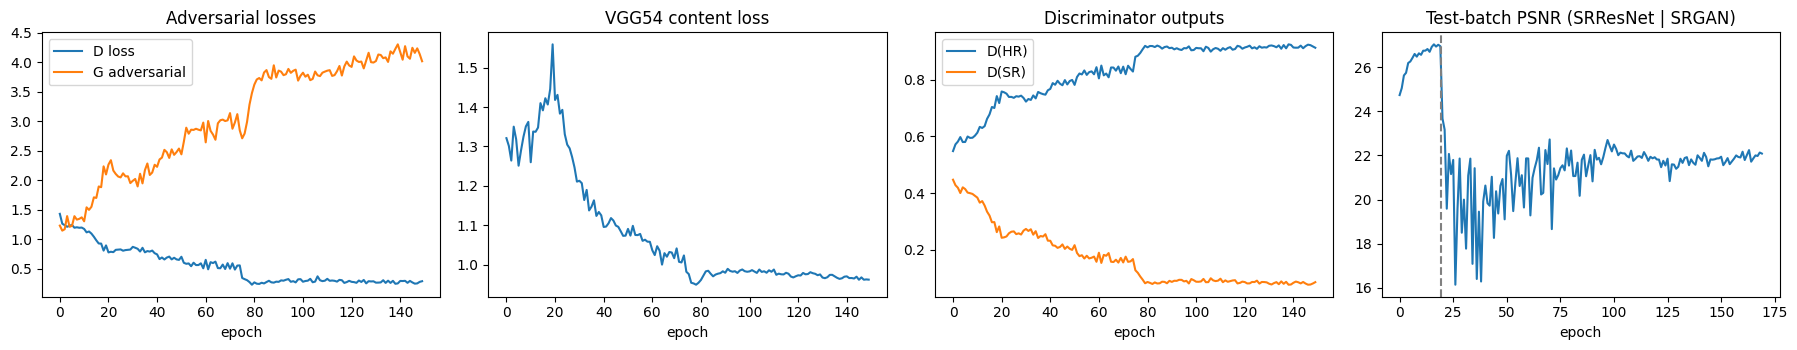

In [14]:
# SRGAN training curves
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].plot(hist_srgan['d_loss'], label='D loss'); ax[0].plot(hist_srgan['adv'], label='G adversarial'); ax[0].legend(); ax[0].set_title('Adversarial losses')
ax[1].plot(hist_srgan['content']); ax[1].set_title('VGG54 content loss')
ax[2].plot(hist_srgan['d_real'], label='D(HR)'); ax[2].plot(hist_srgan['d_fake'], label='D(SR)'); ax[2].legend(); ax[2].set_title('Discriminator outputs')
ax[3].plot(hist_srresnet['psnr'] + hist_srgan['psnr']); ax[3].axvline(len(hist_srresnet['psnr']) - 0.5, ls='--', c='gray')
ax[3].set_title('Test-batch PSNR (SRResNet | SRGAN)')
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); savefig('srgan_training_curves.png'); plt.show()

## 10. Generating 128×128 images with the SRGAN

In [15]:
@torch.no_grad()
def super_resolve(G, X_lr_arr, batch=64):
    G.eval(); out = []
    for i in tqdm(range(0, len(X_lr_arr), batch), desc='Super-resolving'):
        lr = torch.from_numpy(X_lr_arr[i:i+batch]).permute(0, 3, 1, 2).float().div(255).to(device)
        with torch.autocast(device.type, enabled=AMP):
            sr = G(lr).float()
        out.append(((sr.clamp(-1, 1) + 1) * 127.5).round().byte().permute(0, 2, 3, 1).cpu().numpy())
    return np.concatenate(out)

CACHE_SR = os.path.join(DATA_DIR, f'catsdogs_srgan_{IMG_HR}px_{N_PER_CLASS}perclass.npz')
X_sr = super_resolve(G_srgan, X_lr)
np.savez_compressed(CACHE_SR, X=X_sr, y=y)
X_srres = super_resolve(G_srresnet, X_lr[test_idx])   # SRResNet output (test set only, for comparison)
X_bic   = bicubic_up(X_lr[test_idx])                  # bicubic baseline (test set only)
print('SRGAN images:', X_sr.shape)

Super-resolving:   0%|          | 0/188 [00:00<?, ?it/s]

Super-resolving:   0%|          | 0/57 [00:00<?, ?it/s]

SRGAN images: (12000, 128, 128, 3)


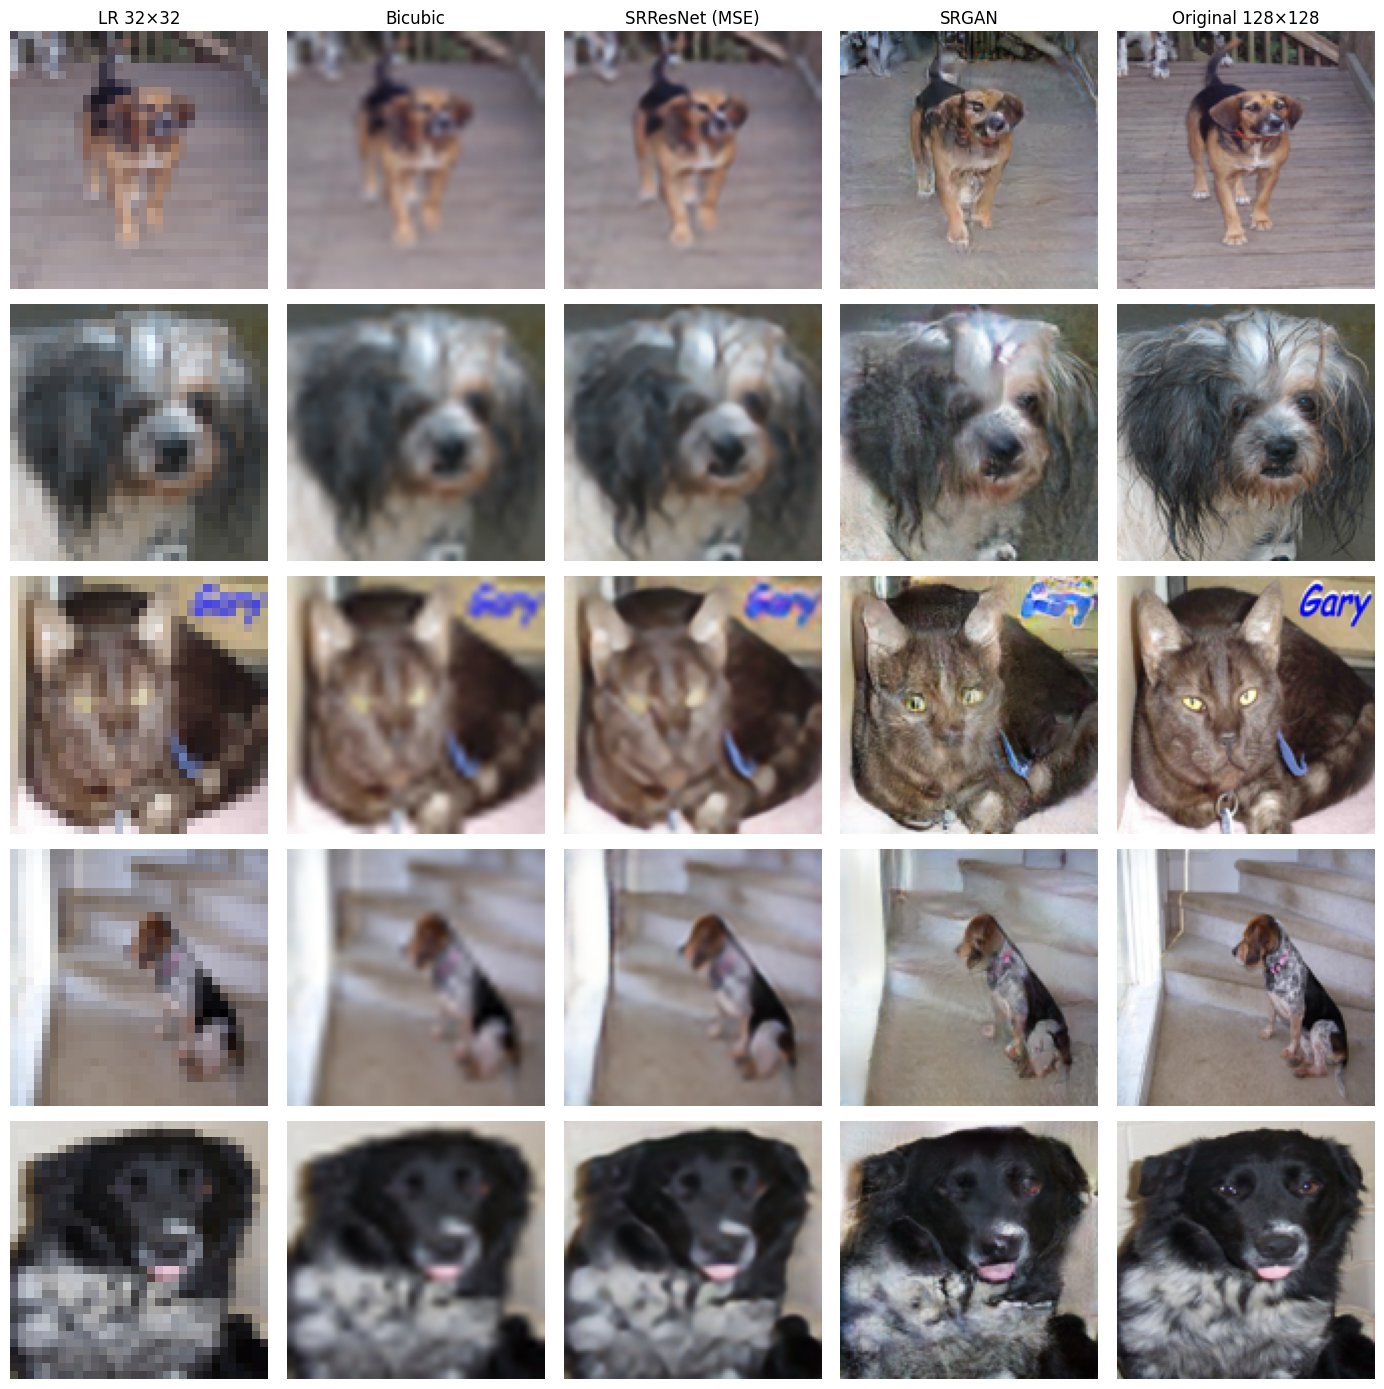

In [16]:
# Visual comparison: LR | bicubic | SRResNet | SRGAN | original HR
cols = ['LR 32×32', 'Bicubic', 'SRResNet (MSE)', 'SRGAN', 'Original 128×128']
fig, axes = plt.subplots(5, 5, figsize=(14, 14))
for r in range(5):
    i = test_idx[r]
    imgs = [X_lr[i], X_bic[r], X_srres[r], X_sr[i], X_hr[i]]
    for c in range(5):
        axes[r, c].imshow(imgs[c], interpolation='nearest' if c == 0 else 'antialiased'); axes[r, c].axis('off')
        if r == 0: axes[r, c].set_title(cols[c])
plt.tight_layout(); savefig('sr_comparison.png'); plt.show()

In [17]:
# Image-quality metrics on the full test set
def quality(X_pred, X_true):
    psnr = np.mean([peak_signal_noise_ratio(t, p, data_range=255) for p, t in zip(X_pred, X_true)])
    ssim = np.mean([structural_similarity(t, p, channel_axis=2, data_range=255) for p, t in zip(X_pred, X_true)])
    return psnr, ssim

X_hr_test = X_hr[test_idx]
iq = pd.DataFrame([quality(X_bic, X_hr_test), quality(X_srres, X_hr_test), quality(X_sr[test_idx], X_hr_test)],
                  index=['Bicubic', 'SRResNet', 'SRGAN'], columns=['PSNR (dB)', 'SSIM']).round(4)
iq.to_csv(os.path.join(RESULTS_DIR, 'image_quality.csv'))
iq

,PSNR (dB),SSIM
Bicubic,25.0155,0.7280
SRResNet,26.4488,0.7787
SRGAN,21.6609,0.6086


## 11. Model B: trained on SRGAN images

modelB epoch 1/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelB | epoch   1 | loss 0.2530 | train acc 0.8879 | test acc 0.9247


modelB epoch 2/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelB | epoch   2 | loss 0.1597 | train acc 0.9355 | test acc 0.9347


modelB epoch 3/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelB | epoch   3 | loss 0.1387 | train acc 0.9413 | test acc 0.9219


... (10 outputs left out)

modelB epoch 9/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelB | epoch   9 | loss 0.0563 | train acc 0.9781 | test acc 0.9339


modelB epoch 10/10:   0%|          | 0/262 [00:00<?, ?it/s]

modelB | epoch  10 | loss 0.0535 | train acc 0.9806 | test acc 0.9272


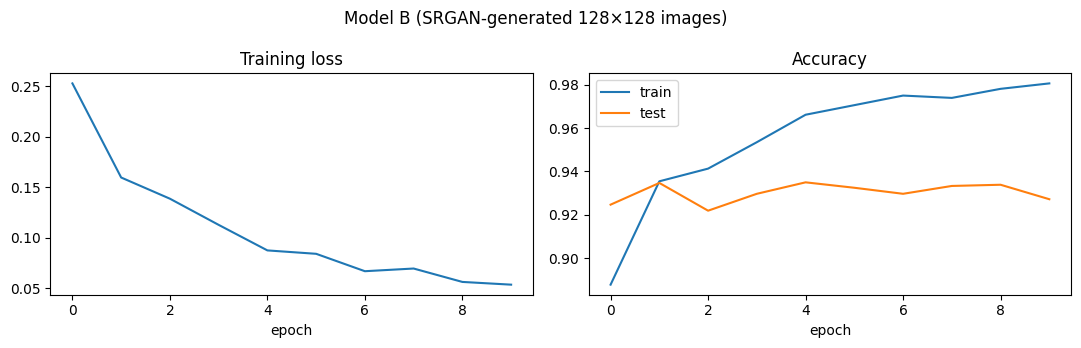

In [18]:
model_B, hist_B = train_classifier('modelB', X_sr[train_idx], y_train, X_sr[test_idx], y_test)
plot_history(hist_B, 'Model B (SRGAN-generated 128×128 images)', 'modelB_history.png')

## 12. Comparison of Model A and Model B

In [19]:
def metrics(y_true, prob):
    pred = (prob > 0.5).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred), 'AUC': roc_auc_score(y_true, prob)}

probs = {
    'Model A → real test':  predict(model_A, X_hr[test_idx], y_test),
    'Model B → SRGAN test': predict(model_B, X_sr[test_idx], y_test),
    'Model A → SRGAN test': predict(model_A, X_sr[test_idx], y_test),
    'Model B → real test':  predict(model_B, X_hr[test_idx], y_test),
}
results = pd.DataFrame({k: metrics(y_test, p) for k, p in probs.items()}).T.round(4)
results.to_csv(os.path.join(RESULTS_DIR, 'classification_metrics.csv'))
results

,Accuracy,Precision,Recall,F1,AUC
Model A → real test,0.9728,0.9666,0.9794,0.9730,0.9970
Model B → SRGAN test,0.9272,0.8980,0.9639,0.9298,0.9843
Model A → SRGAN test,0.9250,0.9386,0.9094,0.9238,0.9817
Model B → real test,0.9569,0.9322,0.9856,0.9581,0.9943


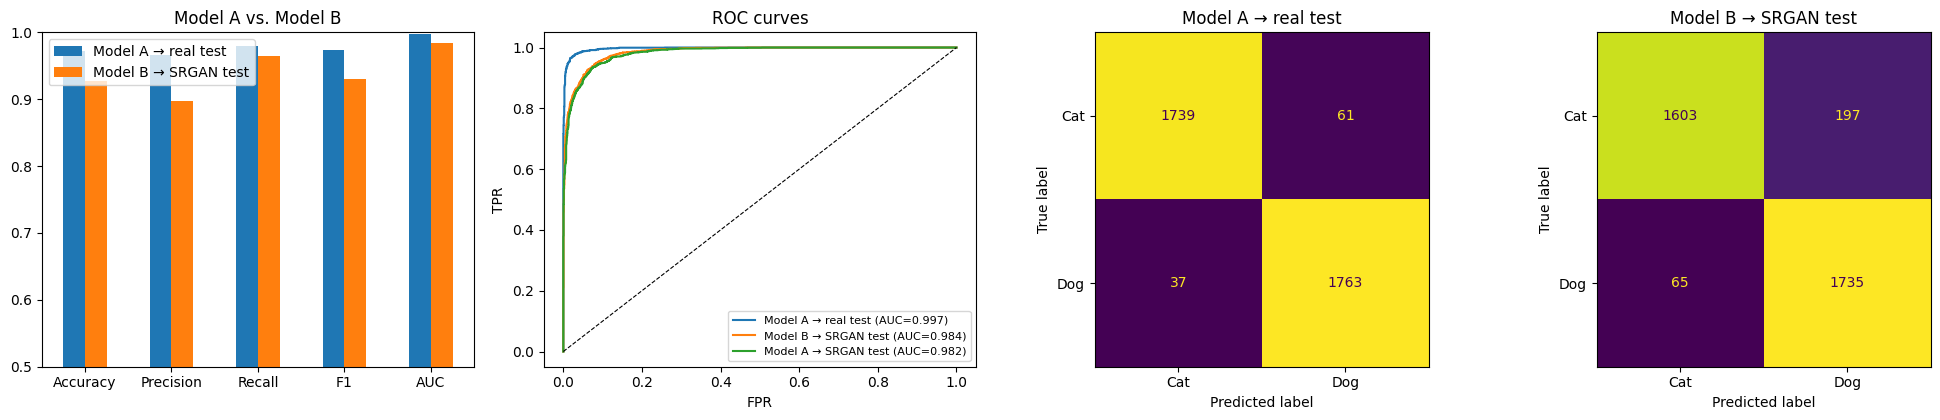

In [20]:
main = ['Model A → real test', 'Model B → SRGAN test']
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
results.loc[main].T.plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(0.5, 1.0); ax[0].set_title('Model A vs. Model B')
for k in main + ['Model A → SRGAN test']:
    fpr, tpr, _ = roc_curve(y_test, probs[k]); ax[1].plot(fpr, tpr, label=f"{k} (AUC={results.loc[k, 'AUC']:.3f})")
ax[1].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); ax[1].set_title('ROC curves'); ax[1].legend(fontsize=8)
for a, k in zip(ax[2:], main):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (probs[k] > 0.5).astype(int)), display_labels=CLASSES).plot(ax=a, colorbar=False)
    a.set_title(k)
plt.tight_layout(); savefig('model_comparison.png'); plt.show()

In [ ]:
summary = {
    'config': {'N_PER_CLASS': N_PER_CLASS, 'train': int(len(train_idx)), 'test': int(len(test_idx)),
               'CLS_EPOCHS': CLS_EPOCHS, 'SRRESNET_EPOCHS': SRRESNET_EPOCHS, 'SRGAN_EPOCHS': SRGAN_EPOCHS,
               'SR_BATCH': SR_BATCH, 'SEED': SEED},
    'classification': results.to_dict(orient='index'),
    'image_quality': iq.to_dict(orient='index'),
}
with open(os.path.join(RESULTS_DIR, 'summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print('\nAll figures, metrics and checkpoints are in:', PROJECT_DIR)